# Eficiencia, riesgo en reclutamiento y análisis crítico del clasificador de texto

En este capítulo ponemos el desempeño junto a su costo (latencia, tamaño, energía), situamos el clasificador en el marco que regula los sistemas de selección de personal y respondemos las preguntas críticas del bloque con la evidencia de los capítulos {doc}`21_nlp_representaciones` a {doc}`24_nlp_robustez_equidad`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, ci, exists, need, pct, style
from project.config import RESULTS

style()
pd.set_option("display.precision", 3)
S = need("analysis/nlp_stats/stats.pkl")
L = S["labels"]
T = S["results"]

## Eficiencia

Medimos la latencia por documento con lote 1, incluida la limpieza del texto, sobre 100 currículos de test (30 para DistilBERT en CPU). Las redes de Keras se miden con la arquitectura elegida y sin reentrenar, porque el tiempo de inferencia depende de la arquitectura y de la longitud de la entrada, no del valor de los pesos.

In [2]:
eff = need("analysis/nlp_efficiency/efficiency.pkl")
eff = eff[eff.device != "—"].copy()
eff["modelo"] = eff.model.map(L)
display(eff[["modelo", "device", "params", "disk_mb", "lat_p50_ms", "lat_p95_ms", "docs_per_s"]].rename(columns={
    "device": "dispositivo", "params": "parámetros", "disk_mb": "disco (MB)", "lat_p50_ms": "latencia p50 (ms)",
    "lat_p95_ms": "latencia p95 (ms)", "docs_per_s": "documentos/s"}).style.hide(axis="index").format(precision=2))

modelo,dispositivo,parámetros,disco (MB),latencia p50 (ms),latencia p95 (ms),documentos/s
TF-IDF + RL,CPU,480024,2.69,2.83,5.05,334.11
NB-SVM,CPU,500024,2.77,2.74,4.80,349.79
TF-IDF + XGBoost,CPU,61672,5.47,6.89,9.63,142.20
FastText,CPU,203408400,814.22,1.09,2.25,825.04
CNN-1D,GPU,2210724,8.84,11.25,15.30,86.75
CNN-1D,CPU,2210724,8.84,11.56,15.33,84.08
BiLSTM,GPU,2106276,8.43,326.21,344.56,3.05
BiLSTM,CPU,2106276,8.43,159.63,167.02,6.23
DistilBERT,GPU,66971928,267.89,18.72,29.45,49.12
DistilBERT,CPU,66971928,267.89,257.32,266.54,3.90


Para XGBoost, la columna de parámetros cuenta los nodos de los árboles, que no son comparables uno a uno con los pesos de una red.

**Energía y CO₂ del entrenamiento.** El monitor de energía midió la potencia del equipo (CPU, GPU y RAM) durante la primera parte del proyecto. Estimamos la energía de entrenamiento de cada modelo como potencia media medida × tiempo de entrenamiento de las 5 semillas, con el factor de emisión que `codecarbon` asigna a Colombia {cite:p}`codecarbon2024`. Es una estimación de orden de magnitud: los modelos ligeros usan menos potencia que la media del equipo durante un entrenamiento en GPU.

In [3]:
cols = ["start", "end", "seconds", "cpu_kwh", "gpu_kwh", "ram_kwh", "total_kwh", "kg_co2eq", "cpu_w", "gpu_w"]
ew = pd.read_csv(RESULTS / "mlops" / "energy_windows.csv", names=cols)
ew = ew[pd.to_numeric(ew.seconds, errors="coerce").notna()].astype({c: float for c in cols[2:]})
watts = 3.6e6 * ew.total_kwh.sum() / ew.seconds.sum()
factor = ew.kg_co2eq.sum() / ew.total_kwh.sum()
en = pd.DataFrame({"modelo": T.index.map(L), "entrenamiento por semilla (s)": T.seconds_train,
                   "kWh (5 semillas)": T.seconds_train * 5 * watts / 3.6e6})
en["g CO₂eq (5 semillas)"] = 1e3 * en["kWh (5 semillas)"] * factor
display(Markdown(f"Potencia media medida: {watts:.0f} W; factor de emisión: {1e3 * factor:.0f} g CO₂eq/kWh."))
en.style.hide(axis="index").format(precision=3)

Potencia media medida: 87 W; factor de emisión: 187 g CO₂eq/kWh.

modelo,entrenamiento por semilla (s),kWh (5 semillas),g CO₂eq (5 semillas)
DistilBERT,141.827,0.017,3.199
CNN-1D,20.772,0.003,0.469
TF-IDF + XGBoost,217.933,0.026,4.916
NB-SVM,11.749,0.001,0.265
BiLSTM,199.903,0.024,4.509
TF-IDF + RL,11.073,0.001,0.250
FastText,49.976,0.006,1.127
Clase mayoritaria,0.001,0.000,0.000


### Frente de Pareto: F1 frente a latencia

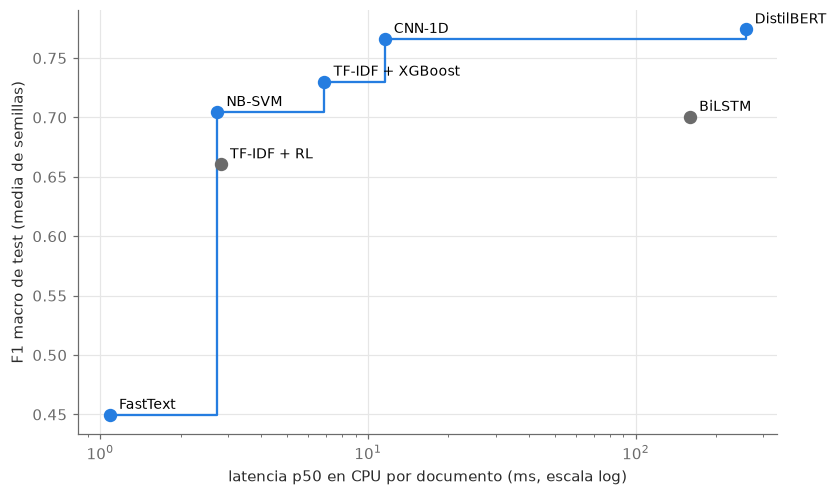

Modelos en el frente de Pareto (ninguno otro es a la vez más rápido y mejor): FastText, NB-SVM, TF-IDF + XGBoost, CNN-1D, DistilBERT.

In [4]:
cpu = eff[eff.device == "CPU"].set_index("model").lat_p50_ms
pts = pd.DataFrame({"f1": T.f1_macro, "lat": T.index.map(lambda m: cpu.get(m, np.nan))}, index=T.index).dropna()
pts = pts.sort_values("lat")
front, best_f1 = [], -1
for m, r in pts.iterrows():
    if r.f1 > best_f1:
        front.append(m); best_f1 = r.f1
fig, ax = plt.subplots(figsize=(7.5, 4.4))
for k, (m, r) in enumerate(pts.iterrows()):
    on = m in front
    ax.scatter(r.lat, r.f1, s=60, color=CAT[0] if on else MUTED, zorder=3)
    ax.annotate(L[m], (r.lat, r.f1), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.plot(pts.loc[front, "lat"], pts.loc[front, "f1"], color=CAT[0], lw=1.5, zorder=2, drawstyle="steps-post")
ax.set(xscale="log", xlabel="latencia p50 en CPU por documento (ms, escala log)", ylabel="F1 macro de test (media de semillas)")
plt.show()
display(Markdown("Modelos en el frente de Pareto (ninguno otro es a la vez más rápido y mejor): " + ", ".join(L[m] for m in front) + "."))

### Cuantización de DistilBERT

Exportamos DistilBERT a ONNX y aplicamos cuantización dinámica int8 a los pesos de las capas lineales. Medimos la F1 macro en 150 documentos de validación y la latencia en CPU con lote 1.

In [5]:
if exists("mlops/bert_quant/bert_quant.pkl"):
    bq = need("mlops/bert_quant/bert_quant.pkl")
    tq = bq["table"]
    display(tq.rename(columns={"variant": "variante", "f1_val": "F1 macro (val)", "lat_p50_ms": "latencia p50 (ms)", "lat_p95_ms": "latencia p95 (ms)",
                               "size_mb": "tamaño (MB)", "agreement_with_fp32": "acuerdo con fp32"}).style.hide(axis="index").format(precision=3, na_rep="—"))
    a, b = tq.iloc[0], tq.iloc[1]
    display(Markdown(f"La cuantización reduce el tamaño {a.size_mb / b.size_mb:.1f} veces y la latencia p50 {a.lat_p50_ms / b.lat_p50_ms:.1f} veces, "
                     f"con un cambio de F1 macro de {b.f1_val - a.f1_val:+.3f} y un acuerdo de predicciones de {pct(b.agreement_with_fp32)} con el modelo fp32."))
else:
    display(Markdown("La medición de cuantización no terminó (`python scripts/mlops.py bert-quant`)."))

variante,F1 macro (val),latencia p50 (ms),latencia p95 (ms),tamaño (MB),acuerdo con fp32
ONNX fp32,0.351,182.344,200.157,268.012,—
ONNX int8 dinámico,0.351,68.185,73.949,67.380,0.947


La cuantización reduce el tamaño 4.0 veces y la latencia p50 2.7 veces, con un cambio de F1 macro de +0.000 y un acuerdo de predicciones de 94.7 % con el modelo fp32.

La destilación ya está incorporada en el propio DistilBERT, que es una versión destilada de BERT-base con 40 % menos parámetros {cite:p}`sanh2019distilbert`. No destilamos un modelo más pequeño a partir de él: con el presupuesto de GPU compartido con la segmentación, priorizamos las semillas y la búsqueda de hiperparámetros.

## Riesgo en reclutamiento

### Marco regulatorio

Un clasificador que asigna una categoría profesional a un currículo es, en la práctica, un componente de un sistema de selección de personal. Tres marcos son relevantes:

- **Unión Europea.** El Reglamento de Inteligencia Artificial clasifica como de **alto riesgo** los sistemas destinados a la contratación o selección de personas, en particular para filtrar solicitudes y evaluar candidatos (anexo III, punto 4) {cite:p}`eu2024aiact`. Para ellos exige un sistema de gestión de riesgos (art. 9), gobernanza de los datos de entrenamiento, incluida la detección de sesgos (art. 10), documentación técnica y registros (arts. 11 y 12), transparencia hacia quien lo usa (art. 13) y **supervisión humana** efectiva (art. 14).
- **Colombia.** La Ley 1581 de 2012 regula el tratamiento de datos personales {cite:p}`colombia2012ley1581`. Un currículo contiene datos personales y, a veces, sensibles; su tratamiento exige autorización previa e informada del titular y una finalidad declarada.
- **Estados Unidos.** Las *Uniform Guidelines on Employee Selection Procedures* introducen la regla de los cuatro quintos: una tasa de selección de un grupo inferior al 80 % de la del grupo con mayor tasa se considera evidencia de impacto adverso {cite:p}`eeoc1978uniform`. Es la regla que aplicamos por clase en el capítulo {doc}`24_nlp_robustez_equidad`.

### Tensiones entre criterios de equidad

Paridad demográfica, igualdad de oportunidades y calibración por grupo no pueden cumplirse a la vez cuando las tasas base difieren entre grupos, salvo con un predictor perfecto {cite:p}`kleinberg2017tradeoffs,chouldechova2017fair`. En estos datos las tasas base difieren: la proporción de currículos con términos femeninos va del 7 % en «Chef» al 39 % en «Apparel» (capítulo {doc}`20_nlp_eda`). Exigir la misma tasa de asignación a «Apparel» en los dos grupos obligaría a clasificar mal a una parte de los documentos de uno de ellos; exigir la misma tasa de verdaderos positivos deja tasas de selección distintas. La elección entre criterios es una decisión normativa de quien despliega el sistema, no una propiedad técnica del modelo.

In [6]:
fz = S["fairness"]
best = S["errors"]["model"]
cf = fz["counterfactual"].set_index("model")
gr = fz["group_rates"]
gb = gr[gr.model == best] if len(gr) else gr
sel = S["selective"]
cov90 = sel[(sel.model == best) & (sel.target_acc == 0.9)].coverage
txt = [f"Para el mejor modelo ({L[best]}): F1 macro de test {T.f1_macro[best]:.3f}"]
if best in cf.index:
    txt.append(f"el contrafactual de género cambia la predicción en el {pct(cf.flip_rate[best])} de los currículos")
if len(gb):
    nflag = int((gb.di_hi < 0.8).sum())
    txt.append(f"{nflag} de {len(gb)} clases evaluables {'tiene' if nflag == 1 else 'tienen'} impacto dispar con IC entero bajo 0.8")
if len(cov90):
    txt.append(f"a exactitud ≥ 0.90 puede decidir solo sobre el {pct(float(cov90.iloc[0]))} de los documentos")
display(Markdown("; ".join(txt) + "."))

Para el mejor modelo (DistilBERT): F1 macro de test 0.774; el contrafactual de género cambia la predicción en el 0.0 % de los currículos; 0 de 7 clases evaluables tienen impacto dispar con IC entero bajo 0.8; a exactitud ≥ 0.90 puede decidir solo sobre el 91.4 % de los documentos.

### ¿Debería usarse automáticamente para decidir sobre personas?

**No.** Las razones vienen de la evidencia de este bloque:

In [7]:
err = 1 - T.accuracy[best]
pt = S["perturbations"]
dcat = pt[(pt.model == best) & (pt.perturbation == "sin_categoria")]
reasons = [f"- **Error frecuente.** La exactitud de {L[best]} en test es {T.accuracy[best]:.3f}: aproximadamente uno de cada {1 / err:.0f} "
           f"currículos queda mal clasificado, y los errores se concentran en profesiones afines, donde una mala asignación significa que el "
           f"candidato no aparece en la búsqueda correcta."]
if len(dcat) and dcat.drop_lo.iloc[0] > 0:
    reasons.append(f"- **Atajo.** Al borrar del texto la palabra de su propia categoría, la F1 macro cae {dcat["drop"].iloc[0]:.3f} "
                   f"[{dcat.drop_lo.iloc[0]:.3f}, {dcat.drop_hi.iloc[0]:.3f}]: parte del desempeño depende de una pista que no existe en "
                   f"currículos que no nombran la categoría a la que aspiran.")
reasons += ["- **Equidad sin certificar.** Las métricas de equidad solo pueden medirse con un indicio débil (términos de género en el texto) "
            "y con grupos pequeños; la ausencia de alertas no certifica equidad.",
            "- **Validez externa desconocida.** El conjunto de datos procede de una sola fuente (la competencia de Kaggle), en inglés y anonimizado con marcadores fijos; no sabemos cómo se "
            "comporta con currículos de otro país, idioma o formato."]
display(Markdown("\n".join(reasons)))

- **Error frecuente.** La exactitud de DistilBERT en test es 0.841: aproximadamente uno de cada 6 currículos queda mal clasificado, y los errores se concentran en profesiones afines, donde una mala asignación significa que el candidato no aparece en la búsqueda correcta.
- **Atajo.** Al borrar del texto la palabra de su propia categoría, la F1 macro cae 0.604 [0.569, 0.641]: parte del desempeño depende de una pista que no existe en currículos que no nombran la categoría a la que aspiran.
- **Equidad sin certificar.** Las métricas de equidad solo pueden medirse con un indicio débil (términos de género en el texto) y con grupos pequeños; la ausencia de alertas no certifica equidad.
- **Validez externa desconocida.** El conjunto de datos procede de una sola fuente (la competencia de Kaggle), en inglés y anonimizado con marcadores fijos; no sabemos cómo se comporta con currículos de otro país, idioma o formato.

Un uso aceptable es como **apoyo a una persona**, con estas salvaguardas:

1. **Decisión humana siempre.** El modelo propone una categoría o una lista corta (el conjunto conforme con α = 0.1) y una persona decide. Ningún candidato se descarta sin revisión humana.
2. **Derivación por confianza.** Por debajo del umbral de confianza fijado en validación, el documento va a revisión completa sin sugerencia.
3. **Auditoría periódica de equidad** con atributos declarados voluntariamente por los candidatos (no inferidos del texto), con la regla de los cuatro quintos y la igualdad de oportunidades por clase.
4. **Monitoreo de deriva** (capítulo {doc}`31_monitoreo_deriva`) y reentrenamiento con datos nuevos etiquetados por personas.
5. **Transparencia**: la tarjeta del modelo (capítulo {doc}`30_mlops`) informa del uso previsto, los usos fuera de alcance, el desempeño por clase y las limitaciones; los candidatos son informados del uso de un sistema automatizado y del tratamiento de sus datos (Ley 1581 de 2012).

## Análisis crítico

### ¿*Transformers* frente a modelos clásicos, una vez controlados presupuesto, semillas y *baselines* fuertes?

In [8]:
h4 = S.get("h4", {})
lines = []
if h4:
    d = h4["diff_bert_minus_xgb"]
    lines.append(f"La diferencia de F1 macro entre DistilBERT y TF-IDF + XGBoost es {ci(d, h4['lo'], h4['hi'])} (H4 "
                 f"{'refutada' if h4['refuted'] else 'no refutada'}). Respecto de δ = 0.02, "
                 + ("el IC cae entero dentro de [−δ, δ]: las dos familias son equivalentes en la práctica."
                    if h4["equivalent"] else
                    ("el IC queda entero por encima de δ: la ventaja de DistilBERT es relevante en la práctica." if h4["lo"] > 0.02 else
                     "el IC queda entero por debajo de −δ: XGBoost supera a DistilBERT en una magnitud relevante." if h4["hi"] < -0.02 else
                     "el IC cruza ±δ: los datos no bastan para decidir si la diferencia es relevante en la práctica.")))
top_cls = T.drop(["distilbert", "majority"], errors="ignore").f1_macro.idxmax()
if "distilbert" in T.index:
    lines.append(f"El mejor modelo clásico o ligero es {L[top_cls]} ({T.f1_macro[top_cls]:.3f}); DistilBERT obtiene {T.f1_macro['distilbert']:.3f} "
                 f"con un tiempo de entrenamiento {T.seconds_train['distilbert'] / T.seconds_train[top_cls]:.0f} veces mayor por semilla.")
display(Markdown(" ".join(lines) if lines else "Sin resultados de DistilBERT."))

La diferencia de F1 macro entre DistilBERT y TF-IDF + XGBoost es 0.039 [-0.002, 0.086] (H4 refutada). Respecto de δ = 0.02, el IC cruza ±δ: los datos no bastan para decidir si la diferencia es relevante en la práctica. El mejor modelo clásico o ligero es CNN-1D (0.766); DistilBERT obtiene 0.774 con un tiempo de entrenamiento 7 veces mayor por semilla.

In [9]:
from project.config import RESULTS as _R
from project.persist import load_pickle as _lp

_ntr = {m: _lp(_R / "nlp" / m / "hpo" / "hpo.pkl")["n_trials_run"] for m in ["tfidf_lr", "nbsvm", "tfidf_xgb", "fasttext", "cnn1d", "bilstm"]
        if (_R / "nlp" / m / "hpo" / "hpo.pkl").exists()}
_nbert = len([d for d in (_R / "nlp" / "distilbert" / "lrgrid").glob("lr_*") if d.is_dir()]) if (_R / "nlp" / "distilbert" / "lrgrid").exists() else 0
_full = [L[m] for m, n in _ntr.items() if n >= 30]
_short = [f"{L[m]} ({n})" for m, n in _ntr.items() if n < 30]
_docs = need("eda/nlp/docs.pkl")
_docs = _docs[_docs.split.isin(["train", "val", "test"])]
_med = float(_docs.n_bert_tokens.median())
_tr = float((_docs.n_bert_tokens > 510).mean())
_nested = sorted(L[m] for m in L if exists(f"nlp/{m}/nested/nested.pkl"))
display(Markdown(
    f"El control es asimétrico. DistilBERT recibió {_nbert} configuraciones de búsqueda (tasa de aprendizaje), frente a 30 *trials* "
    f"de {', '.join(_full)}" + (f" y menos *trials* en {', '.join(_short)}, que agotó su tiempo de búsqueda" if _short else "")
    + ". Ese recorte favorece a los modelos con búsqueda completa, así que una ventaja de DistilBERT sería conservadora y una "
    "desventaja podría reducirse con más búsqueda. "
    + (f"La validación anidada cubre {' y '.join([', '.join(_nested[:-1]), _nested[-1]] if len(_nested) > 1 else _nested)}. " if _nested else "Ningún modelo tiene aún validación anidada completa. ")
    + f"A la vez, la mediana de los currículos es de {_med:.0f} *tokens* WordPiece y DistilBERT solo ve 510 (el {100 * _tr:.0f} % de "
    "los documentos se trunca), mientras que TF-IDF ve el documento entero. Esa diferencia de información es parte de la "
    "comparación, no un sesgo de ella: es lo que cada familia puede hacer con su presupuesto de cómputo."))

El control es asimétrico. DistilBERT recibió 3 configuraciones de búsqueda (tasa de aprendizaje), frente a 30 *trials* de TF-IDF + RL, NB-SVM, TF-IDF + XGBoost, FastText, CNN-1D y menos *trials* en BiLSTM (4), que agotó su tiempo de búsqueda. Ese recorte favorece a los modelos con búsqueda completa, así que una ventaja de DistilBERT sería conservadora y una desventaja podría reducirse con más búsqueda. La validación anidada cubre NB-SVM y TF-IDF + RL. A la vez, la mediana de los currículos es de 975 *tokens* WordPiece y DistilBERT solo ve 510 (el 90 % de los documentos se trunca), mientras que TF-IDF ve el documento entero. Esa diferencia de información es parte de la comparación, no un sesgo de ella: es lo que cada familia puede hacer con su presupuesto de cómputo.


### ¿Impacto del preprocesamiento por familia?

In [10]:
pa = S["prep_ablation"]
if len(pa):
    piv = pa.pivot_table(index="model", columns="pipeline", values="f1_macro")
    piv.index = piv.index.map(lambda m: L.get(m, m))
    piv = piv.rename(columns={"minimal": "mínimo", "standard": "estándar", "aggressive": "agresivo"})
    piv = piv[[c for c in ("mínimo", "estándar", "agresivo") if c in piv.columns]]
    display(piv.rename_axis(columns="nivel de limpieza"))
    full = piv[piv.notna().sum(1) >= 2]
    if len(full):
        rng_ = full.max(1) - full.min(1)
        display(Markdown(f"Rango de F1 macro entre los {full.shape[1]} niveles de limpieza: "
                         + ", ".join(f"{m} {v:.3f}" for m, v in rng_.items()) + "."))
    else:
        display(Markdown("La ablación de preprocesamiento no tiene aún dos niveles medidos para ningún modelo."))

nivel de limpieza,mínimo,estándar,agresivo
model,,,
DistilBERT,0.774,0.781,0.766
TF-IDF + RL,0.605,0.638,0.637


Rango de F1 macro entre los 3 niveles de limpieza: DistilBERT 0.015, TF-IDF + RL 0.033.

Una diferencia entre niveles menor que la DE entre semillas o pliegues significa que la limpieza es una decisión irrelevante para esa familia. El diseño parte de dos supuestos que la ablación pone a prueba: en los modelos de bolsa de palabras, las minúsculas y la eliminación de símbolos reducen el vocabulario sin perder información de clase; en DistilBERT, el *tokenizer* ya normaliza (`uncased`) y la limpieza mínima conserva la puntuación que separa secciones.

In [11]:
from project.stats import corrected_resampled_ttest, holm_adjust as holm

_f = {pl: need(f"nlp/tfidf_lr/cv_{pl}/cv.pkl")["folds"].sort_values("fold") for pl in ("minimal", "standard", "aggressive")
      if exists(f"nlp/tfidf_lr/cv_{pl}/cv.pkl")}
_txt = []
if {"minimal", "standard"} <= set(_f):
    _cmp = [a for a in ("minimal", "aggressive") if a in _f]
    _d = {a: _f["standard"].f1_macro.to_numpy() - _f[a].f1_macro.to_numpy() for a in _cmp}
    _p = {a: corrected_resampled_ttest(-_d[a], int(_f[a].n_train.mean()), int(_f[a].n_test.mean()))[1] for a in _cmp}
    _ph = dict(zip(_cmp, holm(np.array([_p[a] for a in _cmp]))))
    dm = _d["minimal"].mean()
    _txt.append(
        f"**Bolsa de palabras (TF-IDF + RL).** La limpieza estándar supera a la mínima en {dm:+.3f} de F1 macro (p = {_p['minimal']:.3f} "
        f"sin corregir, {_ph['minimal']:.3f} con Holm sobre {len(_cmp)} comparaciones). "
        + ("La dirección apoya el supuesto y la diferencia resiste la corrección."
           if _ph["minimal"] < 0.05 and dm > 0 else
           "La dirección apoya el supuesto, pero con 5 pliegues la diferencia no resiste la corrección: la evidencia es indicativa."
           if dm > 0 else "La dirección contradice el supuesto.")
        + (f" Pasar de estándar a agresiva cambia {-_d['aggressive'].mean():+.3f} (p Holm {_ph['aggressive']:.3f}): quitar URLs, correos "
           "y números y lematizar no aporta nada medible sobre la limpieza estándar." if "aggressive" in _d and _ph["aggressive"] >= 0.05 else ""))
_bert_lv = pa[pa.model == "distilbert"].pipeline.nunique() if len(pa) else 0


def _bert_txt():
    NV = {"minimal": "mínima", "standard": "estándar", "aggressive": "agresiva"}
    b = pa[pa.model == "distilbert"].set_index("pipeline")
    parts = ", ".join(f"{NV[k]} {b.f1_macro[k]:.3f} (DE {b.sd[k]:.3f})" for k in ("minimal", "standard", "aggressive") if k in b.index)
    t = f"Con 3 semillas en validación: {parts}. "
    if {"minimal", "standard"} <= set(b.index):
        d = b.f1_macro["standard"] - b.f1_macro["minimal"]; sd = max(b.sd["standard"], b.sd["minimal"])
        t += (f"La estándar supera a la mínima en {d:+.3f}, " + ("menos de dos DE entre semillas: la limpieza mínima basta, como suponíamos, "
              "coherente con que el *tokenizer* ya normaliza." if abs(d) < 2 * sd else
              "más de dos DE entre semillas: contra el supuesto, la limpieza estándar ayuda también a DistilBERT. Con 3 semillas "
              "lo leemos como indicio, sin contraste formal."))
    if {"aggressive", "standard"} <= set(b.index):
        d2 = b.f1_macro["aggressive"] - b.f1_macro["standard"]
        t += f" La agresiva cambia {d2:+.3f} frente a la estándar" + (", más de dos DE: la limpieza agresiva le resta rendimiento." if d2 < -2 * max(b.sd["aggressive"], b.sd["standard"]) else ".")
    return t
_txt.append("**DistilBERT.** " + ("Tiene un solo nivel medido (el trabajo `bert_prep` no está completo), así que el supuesto "
                                  "de que la limpieza mínima basta queda sin contrastar." if _bert_lv < 2 else
                                  _bert_txt()))
display(Markdown("\n\n".join(_txt)))

**Bolsa de palabras (TF-IDF + RL).** La limpieza estándar supera a la mínima en +0.033 de F1 macro (p = 0.033 sin corregir, 0.067 con Holm sobre 2 comparaciones). La dirección apoya el supuesto, pero con 5 pliegues la diferencia no resiste la corrección: la evidencia es indicativa. Pasar de estándar a agresiva cambia -0.001 (p Holm 0.937): quitar URLs, correos y números y lematizar no aporta nada medible sobre la limpieza estándar.

**DistilBERT.** Con 3 semillas en validación: mínima 0.774 (DE 0.007), estándar 0.781 (DE 0.004), agresiva 0.766 (DE 0.007). La estándar supera a la mínima en +0.007, menos de dos DE entre semillas: la limpieza mínima basta, como suponíamos, coherente con que el *tokenizer* ya normaliza. La agresiva cambia -0.015 frente a la estándar, más de dos DE: la limpieza agresiva le resta rendimiento.


### ¿Qué errores son sistemáticos y qué muestran de los datos?

Comparamos los pares de clases más confundidos por el mejor modelo con los pares que *confident learning* marca como posibles errores de etiqueta.

In [12]:
tp = S["errors"]["top_pairs"].head(8)
noise_pairs = set()
if exists("eda/nlp/label_noise.pkl"):
    iss = need("eda/nlp/label_noise.pkl")["issues"]
    noise_pairs = {tuple(sorted(p)) for p in iss.groupby(["given", "suggested"]).size().sort_values(ascending=False).head(15).index}
tab_e = pd.DataFrame([dict(verdadera=t, predicha=p_, errores=int(n), **{"también entre los 15 pares de ruido": tuple(sorted((t, p_))) in noise_pairs})
                      for (t, p_), n in tp.items()])
display(tab_e.style.hide(axis="index"))
k = int(tab_e["también entre los 15 pares de ruido"].sum())
display(Markdown(f"{k} de los {len(tab_e)} pares más confundidos {'aparece' if k == 1 else 'aparecen'} también entre los 15 pares más frecuentes de posibles errores de etiqueta."))

verdadera,predicha,errores,también entre los 15 pares de ruido
ADVOCATE,HEALTHCARE,4,True
ARTS,PUBLIC-RELATIONS,3,False
ADVOCATE,APPAREL,2,False
ARTS,APPAREL,2,False
AGRICULTURE,BANKING,2,False
BANKING,CONSULTANT,2,False
AUTOMOBILE,AVIATION,2,False
ARTS,CONSULTANT,2,False


1 de los 8 pares más confundidos aparece también entre los 15 pares más frecuentes de posibles errores de etiqueta.

Cuando los pares coinciden, una parte de la frontera entre clases no está definida por el texto: muchos currículos describen trayectorias que pertenecen a dos categorías, y la etiqueta refleja la categoría bajo la que el candidato publicó, no una propiedad verificable del documento. En ese caso el techo de desempeño alcanzable con estas etiquetas está por debajo de 1 por construcción, y la anotación manual de errores (capítulo {doc}`24_nlp_robustez_equidad`) separa los perfiles mixtos de las etiquetas equivocadas.

### Amenazas a la validez

| Tipo | Amenaza | Qué hicimos | Validez de la conclusión |
|---|---|---|---|
| Interna | Fuga entre particiones por casi duplicados | Partición agrupada por casi duplicados (MinHash) y verificación en `make splits` | Válida si los duplicados no detectados son pocos |
| Interna | Sesgo optimista por selección de hiperparámetros | Validación anidada solo en los modelos lineales (enmienda del capítulo {doc}`03_declaracion_apriori`); test sellado y evaluado una vez | Las cifras de validación de los demás modelos conservan el sesgo; las de test, no |
| Interna | Presupuesto de búsqueda desigual | Declarado en el pre-registro; sesga en contra de DistilBERT | Una ventaja de DistilBERT es conservadora |
| Externa | Una sola fuente, en inglés, anonimizada de forma incompleta con marcadores fijos (*Company Name*, *City*, *State*) | Perturbación «sin geografía» | No generaliza a otros países, idiomas o fuentes sin reevaluar |
| Constructo | La etiqueta es la categoría de publicación, no la profesión verificada | Ruido de etiquetas y reentrenamiento sin documentos marcados | La F1 mide acuerdo con la categoría publicada |
| Constructo | El género se infiere de términos del texto | Contrafactual + subgrupos, declarados como indicio | Las métricas de equidad son indicativas |
| Conclusión estadística | 373 documentos de test, 24 clases (≈ 15 por clase) | IC *bootstrap*, Holm, McNemar exacto, Nadeau–Bengio | Diferencias de F1 macro menores que la semiamplitud del IC pareado (tabla de abajo) quedan dentro del ruido de muestreo |

In [13]:
_P = S["pairwise"]
_hw = ((_P.hi - _P.lo) / 2) if {"hi", "lo"} <= set(_P.columns) else None
if _hw is not None and len(_hw):
    display(Markdown(f"Semiamplitud del IC 95 % de la diferencia de F1 macro entre pares de modelos en test: de {_hw.min():.3f} a "
                     f"{_hw.max():.3f} (mediana {_hw.median():.3f}). Una diferencia menor que esa magnitud no distingue a los modelos."))

Semiamplitud del IC 95 % de la diferencia de F1 macro entre pares de modelos en test: de 0.035 a 0.057 (mediana 0.046). Una diferencia menor que esa magnitud no distingue a los modelos.